In [ ]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from mplc_inverse_design.mplc_model import MPLCSystem
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom
from mplc_inverse_design.apply_complex_map import apply_complex_map

/Users/yinzi/Library/CloudStorage/OneDrive-UniversiteitLeiden/Documents/repos/mplc-inverse-design/.venv/lib/python3.13/site-packages/zodiax/stats.py:24: SyntaxWarning: invalid escape sequence '\m'
  Calculates the z-score $(\mu - x) / \sigma$ of a value given a mean and standard
/Users/yinzi/Library/CloudStorage/OneDrive-UniversiteitLeiden/Documents/repos/mplc-inverse-design/.venv/lib/python3.13/site-packages/zodiax/stats.py:46: SyntaxWarning: invalid escape sequence '\m'
  Calculates the squared Mahalanobis distance $(\mu - x)^\top\Sigma^{-1}(\mu - x)$


In [2]:
#Define MPLC parameters
diameter = 9e-3  # Aperture diameter
num_planes = 4  # Number of phase screens
total_length = 50.0e-2 # Initial total length of the system
center_wavel = 632e-9  # Center wavelength for the system
wavelengths = np.array([center_wavel])  # Wavelengths of the input modes

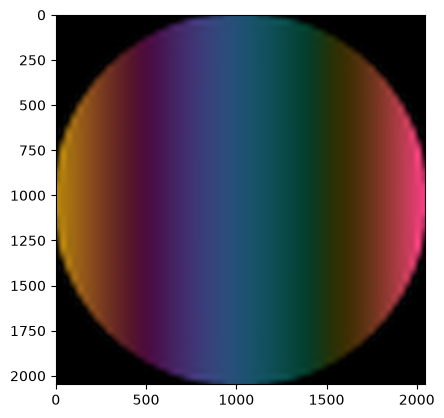

In [3]:
#Load input mode
input_mode = np.load('mplc_input_single_mode.npy')
wf_npixels = 2048  # Number of pixels in the wavefront

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

#interpolate input mode to match wf_npixels using zoom
input_mode = zoom(input_mode, (wf_npixels / input_mode.shape[0], wf_npixels / input_mode.shape[1]), order=3)

plt.figure()
plt.imshow(apply_complex_map(input_mode))

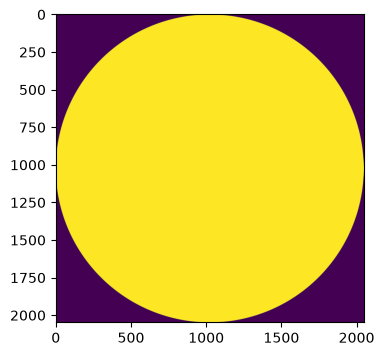

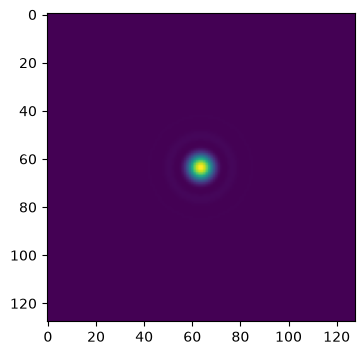

In [4]:
#Calculate output mode
focal_length = 50.0e-2  # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront
circ_aper = dlu.circular_aperture(npixels=wf_npix, diameter = diameter, oversample=5)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 128
#psf_pixel_scale = 20 * focal_length * center_wavel / diameter / psf_npix  # Pixel scale in the PSF plane
psf_pixel_scale = diameter / wf_npix  # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

plt.figure(figsize=(15, 4))
plt.imshow(circ_aper)

plt.figure(figsize=(15, 4))
plt.imshow(np.abs(output_mode)**2)

In [ ]:
mplc_system = MPLCSystem(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    diameter = diameter,
    num_planes = num_planes,
    total_length = total_length,
    target_coordspec_n = psf_npix,
    target_coordspec_d = psf_pixel_scale,
    wavelengths = wavelengths
)

In [ ]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc_system.wf_npixels, mplc_system.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc_system.wf_npixels, mplc_system.wf_npixels))

In [ ]:
#Define wavefront matching loss function
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM(params, mplc_system):
    mplc_system = mplc_system.set("mplc.phase_screens", params["phase_screens"])
    mplc_system = mplc_system.set("mplc.total_length", params["total_length"])

    #propagate every input mode through the MPLC system
    res = mplc_system()

    #calculate the loss (summed over wavelengths and modes)
    #expand the target modes to match the shape of res
    target_modes_expanded = np.expand_dims(mplc_system.target_modes, axis=1)

    #calculate the overlap integral between the output modes and the target modes
    overlap = np.sum(np.conj(res) * target_modes_expanded, axis=(-2, -1))

    #calculate the loss as 1 - the mean of the squared magnitude of the overlap
    loss = 1 - np.mean(np.abs(overlap)**2)
    return loss

In [ ]:
params = {
    "phase_screens": initial_phase_screens,
    "total_length": np.array(total_length),
}

optimizers = {
    "phase_screens": optax.adam(learning_rate=1e-2),
    "total_length": optax.adam(learning_rate=1e-3),
}
optim, opt_state = zdx.map_optimisers(params, optimizers)

#test the loss function
initial_loss, initial_grad = loss_fn_WFM(params, mplc_system)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

Initial loss: 0.99997467
Initial gradient norm: 7.3315423e-06


In [ ]:
# Run the optimisation loop
losses, params_out = [], []
num_iters = 1000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_fn_WFM(params, mplc_system)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/1000 [00:00<?, ?it/s]

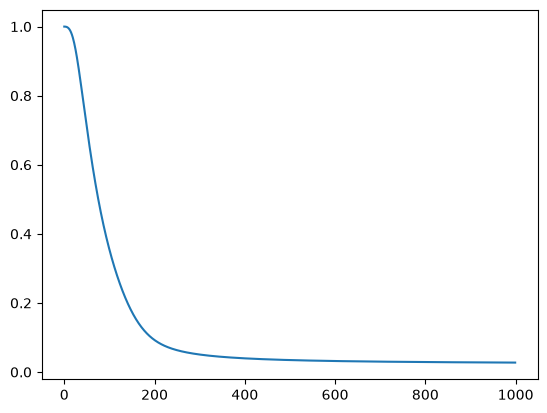

In [10]:
plt.figure()
plt.plot(losses)

0.5


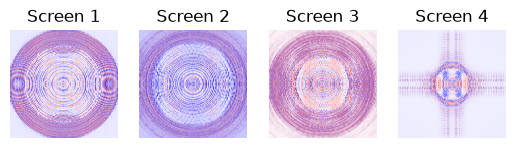

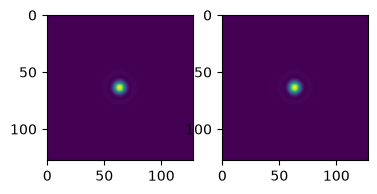

In [ ]:
#plot the final phase screens
phase_screens_final = params["phase_screens"]

np.save('phase_screens_final.npy', phase_screens_final)

plt.figure()
for n in range(num_planes):
    plt.subplot(1, num_planes, n+1)
    plt.imshow(phase_screens_final[n], cmap='seismic')
    plt.title(f'Screen {n+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
mplc_system_final = mplc_system.set("mplc.phase_screens", phase_screens_final).set("mplc.total_length", params["total_length"])
res_final = mplc_system_final()

print(params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)

In [ ]:
#smooth out phase screens with regularization
def smoothness_loss(phase_screens):
    gx = (phase_screens[:, 1:, :] - phase_screens[:, :-1, :])
    gy = (phase_screens[:, :, 1:] - phase_screens[:, :, :-1])
    return np.mean(gx**2) + np.mean(gy**2)

@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_with_smoothing(params, mplc_system, lambda_smooth):
    phase_screens = params["phase_screens"]

    overlap_loss, _ = loss_fn_WFM(params, mplc_system)
    smooth_loss = smoothness_loss(phase_screens)

    return overlap_loss + lambda_smooth * smooth_loss

In [ ]:
# Run the optimisation loop
losses_smoothing, params_out_smoothing = [], []
num_iters = 600
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_with_smoothing(params, mplc_system, lambda_smooth=1e-1)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        #params_out_smoothing.append(params)
        losses_smoothing.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses_smoothing = np.array(losses_smoothing)

Gradient Descent:   0%|          | 0/600 [00:00<?, ?it/s]

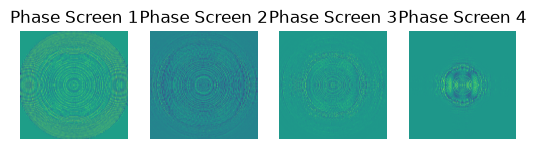

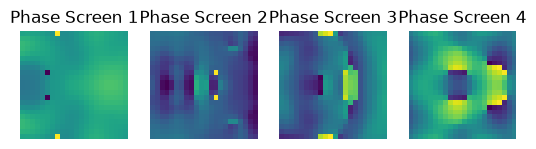

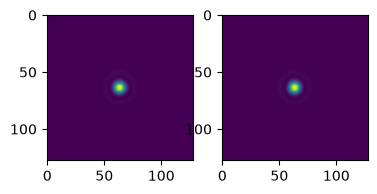

In [ ]:
#plot the final phase screens
phase_screens_final = params["phase_screens"]

plt.figure()
for n in range(num_planes):
    plt.subplot(1, num_planes, n+1)
    plt.imshow(phase_screens_final[n])
    plt.title(f'Phase Screen {n+1}')
    plt.axis('off')

#plot the middle of the phase screens on a 100 um by 100 um area
pix_sub_area = 100e-6 / (diameter / wf_npix)  # Number of pixels corresponding to 100 um
plt.figure()
for n in range(num_planes):
    plt.subplot(1, num_planes, n+1)
    plt.imshow(phase_screens_final[n][wf_npix//2 - int(pix_sub_area/2):wf_npix//2 + int(pix_sub_area/2), 
                                       wf_npix//2 - int(pix_sub_area/2):wf_npix//2 + int(pix_sub_area/2)])
    plt.title(f'Phase Screen {n+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
mplc_system_final = mplc_system.set("mplc.phase_screens", phase_screens_final).set("mplc.total_length", total_length)
res_final = mplc_system_final()

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)